In [6]:
import numpy as np
import pandas as pd
import itertools
import math
import matplotlib.pyplot as plt

In [15]:
markerlist=[".",",","o","v","^","<",">","1","2","3","4","8","s","p","P","*","h","H","+","x","X","D","d","|","_","1","2","3","4","8","none","$\\sigma$"]

hatchlist=['//', '\\\\', '||', '--', '++', 'xx', 'oo', 'OO', '..', '**','/o', '\\|', '|*', '-\\', '+o', 'x*', 'o-', 'O|', 'O.', '*-', '/', '\\', '|', '-', '+', 'x', 'o', 'O', '.', '*']   #hatch list plt matplotlib only 

colorlist = []  #color list
for i in range(10000):
    colorlist.append('#%06X' % np.random.randint(0, 0xFFFFFF))  # colors list

print("color : {} marker : {} hatch : {}".format(colorlist[0],markerlist[0],hatchlist[0]))

color : #C3986B marker : . hatch : //


<div style="background-color:red;color:white">
<hr>
<div style="background-color:indigo;color:cyan;font-size:30px"><b>Summary CLT =P Mu |< Std </b></div></b>
<hr>
sample proportion is equal to population proportion  <br>
sample proportion std is smaller than the population proportion std.
<hr>
sample mean $\bar x$ is identical with population mean $\mu$<br>
sample std s is less than population std $\sigma$( &emsp; <mark>why $\sqrt{n}$ - because its squared during varaice calculation </mark> &emsp; )
<hr>
  <div style="font-size:30px;font-weight:bold;color:yellow;background-color:indigo"> Idea :use a sample to estimate a population </div>
 <hr>
    <ol>
      <li>How may samples of size "n" are possible out of a population of size "N"?  
    <br>$_NC_n$  &emsp;  $_{27}C_5$  &emsp;&rarr;&emsp;$\frac{27!}{(27-5)! \cdot 5!} = 80730$
    <br>math.factorial(27) / (math.factorial(27-5)*math.factorial(5))==math.comb(27,5) True</li>
        <li>Sampling Distribution of Satistics 
        <mark> ( mean | median ,
           proportion ,
           std  | variance....)  </mark></li>
        <li>Assume you take all the possiblbe samples of size "n" and find the required statistics(eg. mean) for each sample. 
            <br>In the case of 27 select 5 , there are 80730 means , or std, or protions .....</li>
        <li>If you orgnize all of those stastistics of each different sample into a table, thiss a sampling distribution. </li>
        <li>Example: (1,2,5) proportion of the odd numbers is $\frac{2}{3}$ &rarr; population proportion ( P = $\frac{2}{3}$)  sample proportion $\widehat p$ 
        <br> Take all the possible samples of size n =2 combinations: (1, 2) (1, 5) (2, 5)</li>
    </ol>
<hr>

In [7]:
pd.set_option('display.max_colwidth', None)
math.comb(3,2)
lst=[1,2,5]
n=2 
from itertools import combinations_with_replacement ,permutations
comb=combinations_with_replacement(lst,n)

cmb=[]
for i in comb:
    cmb.append(i)

perm=permutations(lst,n)
for j in perm:
    cmb.append(j)

unq=[]
for i in cmb:
    if i not in unq:
        unq.append(i)
    else:
        pass
unq_comb= sorted(unq)
# =============prob ---================================
prob       =np.zeros(len(unq_comb),dtype="object")
prob_p     =np.zeros(len(unq_comb),dtype="object")
prob_p_hat =np.zeros(len(unq_comb),dtype="object")
prob_p_hat1=np.zeros(len(unq_comb),dtype="object")
# prob_phat =np.zeros(len(unq_comb),dtype="object")

for i in range(len(unq_comb)):
    prob[i]       ="$\\frac{1}{9}$"
    prob_p[i]     ="$\\frac{2}{3}$"
prob_p_hat1       =["$\\frac{1}{9}$",
                    "$\\frac{1}{18}$",
                    "$\\frac{1}{9}$",
                    "$\\frac{1}{18}$",
                    "$\\frac{0}{9}$",
                    "$\\frac{1}{18}$",
                    "$\\frac{1}{9}$",
                    "$\\frac{1}{18}$",
                    "$\\frac{1}{9}$"]
# =============prob hat================================

colst=[]
for i in range(len(unq_comb)):
    count= 0
    for j in range(len(unq_comb[i])):
        if unq_comb[i][j]%2!=0:
            count=count+1
        colst.append(count)
colst
odd_prob=[]
for i in (np.arange(1,19,2)):
   odd_prob.append( colst[i]/len(unq_comb[n]) )
odd_prob

prob_p_hat=np.around(np.array(odd_prob)/len(unq_comb),2)

df=pd.DataFrame({ "comb":unq_comb,
                  "p":prob_p,
                   "$\\frac{1}{9_{-Opts}}$":prob,
                   "$\\frac{n}{2}$":odd_prob,
                   "$\\widehat p $":prob_p_hat,
                   "$\\widehat p \\frac{n}{9}$":prob_p_hat1,                  
                   "$\\widehat p \\Sigma$":prob_p},
                    
                  index=np.arange(1,10,1)) 
df.columns.name="N=3 n=2 #odd"
df.index.name="9 CombPerm"
df['$\\mu$']="$\\frac{8}{3}$"

sof_cm2=[]
for i in range(len(unq_comb)):
    sof_cm2.append(int( (unq_comb[i][0])+(unq_comb[i][1]) )/2)
df["$\\bar x_{i}$"]= sof_cm2   

df['Comments$ \\quad =\\mu$ p']=[     "1_proportion",
                                     "$\\widehat p=p$",
                                     "$\\widehat p$ etsimates $p$  ",
                                     "$\\Sigma p \\quad {} \\quad Toatl\\ Choice :{}$".format(df["$\\frac{n}{2}$"].sum(),9),
                                     "$\\frac{24}{9}=\\frac{8}{3} \\quad \\frac{6}{9}=\\frac{2}{3}    \\quad $",
                                     "2_mean",
                                     "$\\bar x = \\mu$",
                                     "$\\bar x $ estimates $\\mu$",
                                     "$\\Sigma \\bar x_i  \\quad {}  \\quad Toatl\\ Choice :{} $".format( df["$\\bar x_{i}$"].sum(),9) ]
df["$SES<\\sigma$"] =[   "1 STD SEM",
                         "Not a good estimator",
                         "Reason : is that the proportion and means have already been averaged",
                         " eliminating outliers such as min and max values",
                         "Therefore, its always smaller than the population",
                         "$SEM|SEP=\\sqrt{\\frac{\\sigma \\cdot \\sigma }{n}} \\quad| \\quad \\sqrt{\\frac{p \\cdot q }{n}}$",
                         "Sample size n $\\geq30$",
                         "npq$\\geq10$",
                         "Correction_factor = $\\sqrt{\\frac{N-n}{N-1}}$"]
df

N=3 n=2 #odd,comb,p,$\frac{1}{9_{-Opts}}$,$\frac{n}{2}$,$\widehat p $,$\widehat p \frac{n}{9}$,$\widehat p \Sigma$,$\mu$,$\bar x_{i}$,Comments$ \quad =\mu$ p,$SES<\sigma$
9 CombPerm,,,,,,,,,,,
1,"(1, 1)",$\frac{2}{3}$,$\frac{1}{9}$,1.0,0.11,$\frac{1}{9}$,$\frac{2}{3}$,$\frac{8}{3}$,1.0,1_proportion,1 STD SEM
2,"(1, 2)",$\frac{2}{3}$,$\frac{1}{9}$,0.5,0.06,$\frac{1}{18}$,$\frac{2}{3}$,$\frac{8}{3}$,1.5,$\widehat p=p$,Not a good estimator
3,"(1, 5)",$\frac{2}{3}$,$\frac{1}{9}$,1.0,0.11,$\frac{1}{9}$,$\frac{2}{3}$,$\frac{8}{3}$,3.0,$\widehat p$ etsimates $p$,Reason : is that the proportion and means have already been averaged
4,"(2, 1)",$\frac{2}{3}$,$\frac{1}{9}$,0.5,0.06,$\frac{1}{18}$,$\frac{2}{3}$,$\frac{8}{3}$,1.5,$\Sigma p \quad 6.0 \quad Toatl\ Choice :9$,eliminating outliers such as min and max values
5,"(2, 2)",$\frac{2}{3}$,$\frac{1}{9}$,0.0,0.00,$\frac{0}{9}$,$\frac{2}{3}$,$\frac{8}{3}$,2.0,$\frac{24}{9}=\frac{8}{3} \quad \frac{6}{9}=\frac{2}{3} \quad $,"Therefore, its always smaller than the population"
6,"(2, 5)",$\frac{2}{3}$,$\frac{1}{9}$,0.5,0.06,$\frac{1}{18}$,$\frac{2}{3}$,$\frac{8}{3}$,3.5,2_mean,$SEM|SEP=\sqrt{\frac{\sigma \cdot \sigma }{n}} \quad| \quad \sqrt{\frac{p \cdot q }{n}}$
7,"(5, 1)",$\frac{2}{3}$,$\frac{1}{9}$,1.0,0.11,$\frac{1}{9}$,$\frac{2}{3}$,$\frac{8}{3}$,3.0,$\bar x = \mu$,Sample size n $\geq30$
8,"(5, 2)",$\frac{2}{3}$,$\frac{1}{9}$,0.5,0.06,$\frac{1}{18}$,$\frac{2}{3}$,$\frac{8}{3}$,3.5,$\bar x $ estimates $\mu$,npq$\geq10$
9,"(5, 5)",$\frac{2}{3}$,$\frac{1}{9}$,1.0,0.11,$\frac{1}{9}$,$\frac{2}{3}$,$\frac{8}{3}$,5.0,$\Sigma \bar x_i \quad 24.0 \quad Toatl\ Choice :9 $,Correction_factor = $\sqrt{\frac{N-n}{N-1}}$


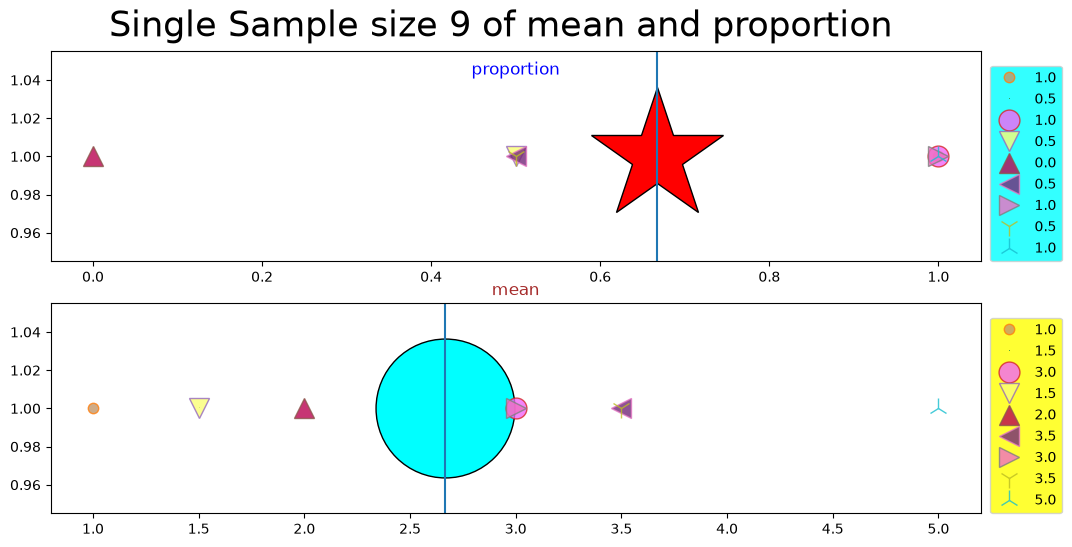

In [48]:
p=2/3
p_hat=p

mean_p=8/3
mean_s=mean_p

fig,ax=plt.subplots(2,1,figsize=(12,6))

ax[0].plot(p,1,marker="*",ms=100,mfc="red",mec="black")
ax[1].plot(mean_p,1,marker="o",ms=100,mfc="cyan",mec="black")

for i in range(9):
    ax[0].plot(odd_prob[i],1,marker=markerlist[i],mfc=colorlist[i],ls="",lw=0.3,ms=15,alpha=0.8, label="{}".format(odd_prob[i]))
    ax[1].plot(sof_cm2[i] ,1,marker=markerlist[i],mfc=colorlist[i],ls="",lw=0.3,ms=15,alpha=0.8, label="{}".format(sof_cm2[i]))
    ax[0].legend(loc=(1.01,0),facecolor="cyan")
    ax[1].legend(loc=(1.01,0),facecolor="yellow")

    ax[0].set_title("proportion",y=0.85,color="blue")
    ax[1].set_title("mean",color="brown")
    # ax[1].axis("off")
    # ax[0].axis("off")
    
ax[0].axvline(p)
ax[1].axvline(mean_p)
plt.suptitle("Single Sample size 9 of mean and proportion",y=0.95,size=25)
plt.savefig("x.pdf")